In [7]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

2026-01-19 09:32:34 [INFO] adopt2g.inference: Loading ensemble from /home/michele/workdir/ADOPT2g/models/seed883_n7/manifest.json...
2026-01-19 09:32:34 [INFO] adopt2g.inference:   Ensemble ID: seed883_n7
2026-01-19 09:32:34 [INFO] adopt2g.inference:   Ensemble size: 7
2026-01-19 09:32:34 [INFO] adopt2g.inference:   Temperature scaling factor: 0.8156
2026-01-19 09:32:34 [INFO] adopt2g.inference:   Uncertainty calibration factor: 7.7745
2026-01-19 09:32:34 [INFO] adopt2g.inference:   Loading ESM model to cuda...
2026-01-19 09:32:35 [WARNING] adopt2g.embeddings: Flash Attention 2 not available (libcudart.so.12: cannot open shared object file: No such file or directory), falling back to sdpa attention
Some weights of EsmModel were not initialized from the model checkpoint at facebook/esm2_t33_650M_UR50D and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/home

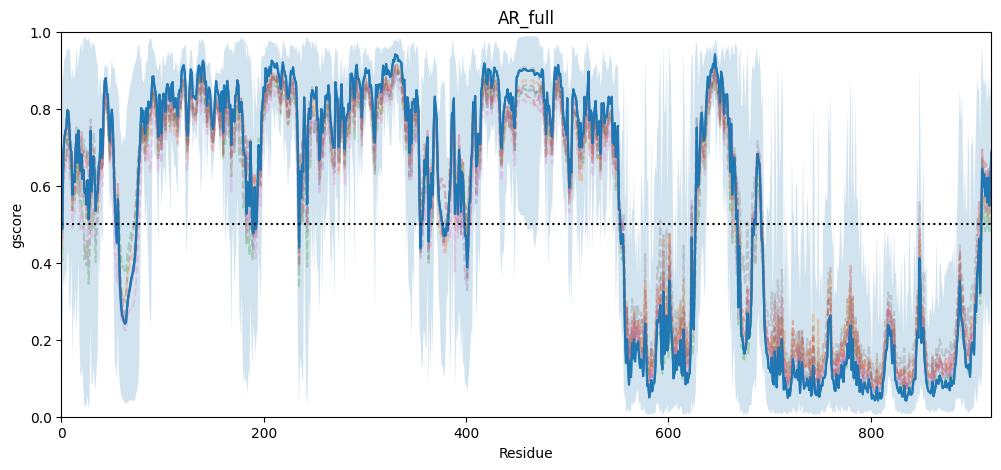

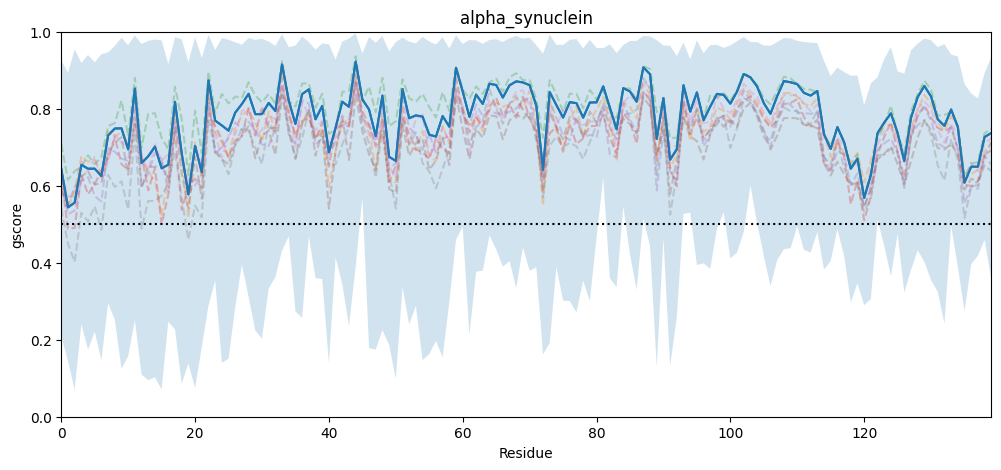

In [8]:
!adopt2g-predict --input ar.fasta --out ar-adopt2g.csv --save #--ensemble-manifest /home/michele/workdir/ADOPT2g/models/seed883_n7-128_64/manifest.json

df = pd.read_csv(
    "ar-adopt2g.csv",
    index_col="label",
    converters={
        "gscores": lambda x: np.asarray(json.loads(x), dtype=float),
        "gscores_lower": lambda x: np.asarray(json.loads(x), dtype=float),
        "gscores_upper": lambda x: np.asarray(json.loads(x), dtype=float),
        "member_gscores": lambda x: np.asarray(json.loads(x), dtype=float),
    },
)

for label, row in df.iterrows():
    gscores = row["gscores"]
    gscores_lower = row["gscores_lower"]
    gscores_upper = row["gscores_upper"]
    member_gscores = row["member_gscores"]

    plt.figure(figsize=(12, 5))
    plt.title(label)
    plt.plot(gscores)
    plt.fill_between(range(len(gscores)), gscores_lower, gscores_upper, alpha=0.2)
    plt.plot(member_gscores.T, alpha=0.3, ls="--")
    plt.plot(gscores, c="C0")
    plt.axhline(0.5, color="k", linestyle=":")
    plt.ylim(0, 1)
    plt.margins(x=0)
    plt.xlabel("Residue")
    plt.ylabel("gscore")
    plt.show()


2026-01-19 09:32:41 [INFO] adopt2g.inference: Loading ensemble from /home/michele/workdir/ADOPT2g/models/seed883_n7/manifest.json...
2026-01-19 09:32:41 [INFO] adopt2g.inference:   Ensemble ID: seed883_n7
2026-01-19 09:32:41 [INFO] adopt2g.inference:   Ensemble size: 7
2026-01-19 09:32:41 [INFO] adopt2g.inference:   Calibration disabled (using raw predictions)
2026-01-19 09:32:41 [INFO] adopt2g.inference:   Loading ESM model to cuda...
2026-01-19 09:32:41 [WARNING] adopt2g.embeddings: Flash Attention 2 not available (libcudart.so.12: cannot open shared object file: No such file or directory), falling back to sdpa attention
Some weights of EsmModel were not initialized from the model checkpoint at facebook/esm2_t33_650M_UR50D and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/home/michele/miniforge3/envs/adopt2g/lib/python3.12/site-packages/torch/cuda/__in

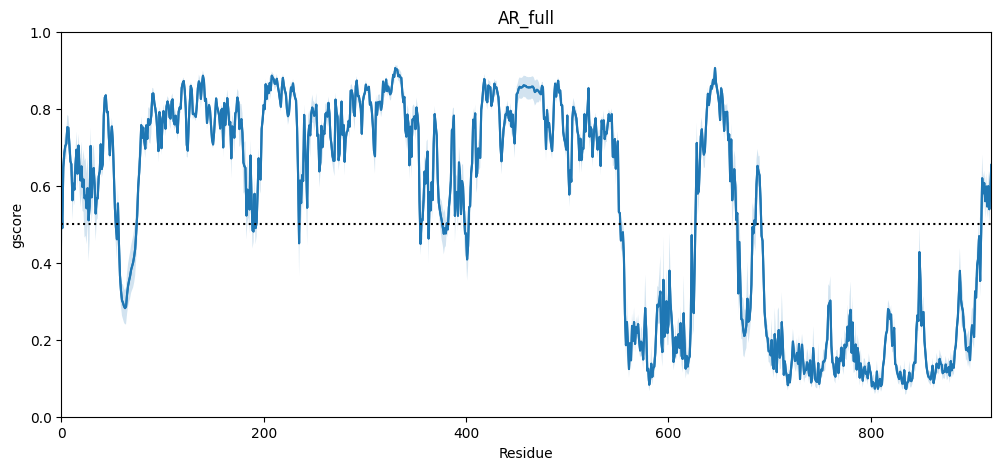

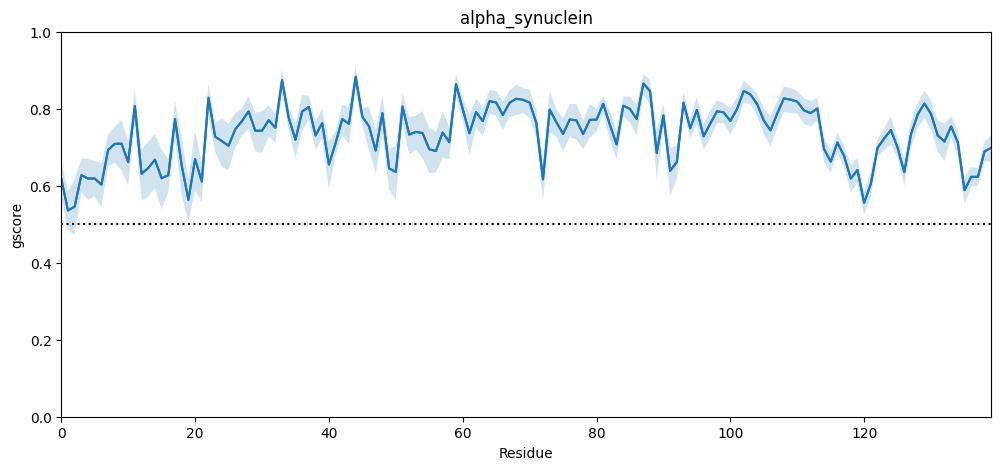

In [9]:
!adopt2g-predict --input ar.fasta --out ar-adopt2g-no.csv --no #--ensemble-manifest /home/michele/workdir/ADOPT2g/models/seed883_n7-128_64/manifest.json
# !adopt2g-catboost predict --input ar.fasta --out ar-adopt2g-no.csv

df = pd.read_csv(
    "ar-adopt2g-no.csv",
    index_col="label",
    converters={
        "gscores": lambda x: np.asarray(json.loads(x), dtype=float),
        "gscores_lower": lambda x: np.asarray(json.loads(x), dtype=float),
        "gscores_upper": lambda x: np.asarray(json.loads(x), dtype=float),
        "member_gscores": lambda x: np.asarray(json.loads(x), dtype=float),
    },
)

for label, row in df.iterrows():
    gscores = row["gscores"]
    gscores_lower = row["gscores_lower"]
    gscores_upper = row["gscores_upper"]

    plt.figure(figsize=(12, 5))
    plt.title(label)
    plt.plot(gscores)
    plt.fill_between(range(len(gscores)), gscores_lower, gscores_upper, alpha=0.2)
    plt.plot(gscores, c="C0")
    plt.axhline(0.5, color="k", linestyle=":")
    plt.ylim(0, 1)
    plt.margins(x=0)
    plt.xlabel("Residue")
    plt.ylabel("gscore")
    plt.show()

In [10]:
df_saxs = pd.read_csv(
    "../../peptonebench/datasets/PeptoneDB-SAXS/PeptoneDB-SAXS.csv",
    index_col="label",
    converters={"gscores_adopt2": lambda x: np.asarray(json.loads(x), dtype=float)},
)
print(df_saxs.columns)
df_saxs_new = pd.read_csv(
    "PeptoneDB-SAXS-adopt2g.csv",
    index_col="label",
    converters={"gscores": lambda x: np.asarray(json.loads(x), dtype=float)},
)
print(df_saxs_new.columns)

assert df_saxs.index.equals(df_saxs_new.index)

Index(['sequence', 'length', 'pH', 'mean_gscore_adopt2', 'gscores_adopt2'], dtype='object')
Index(['sequence', 'mean_gscore', 'mean_gscore_lower', 'mean_gscore_upper',
       'gscores', 'gscores_lower', 'gscores_upper'],
      dtype='object')


old: tot_disodered=59
new: tot_disodered=64
entry with max diff: SASDB85
  old: 0.5088792934431045
  new: 0.2377275855608294


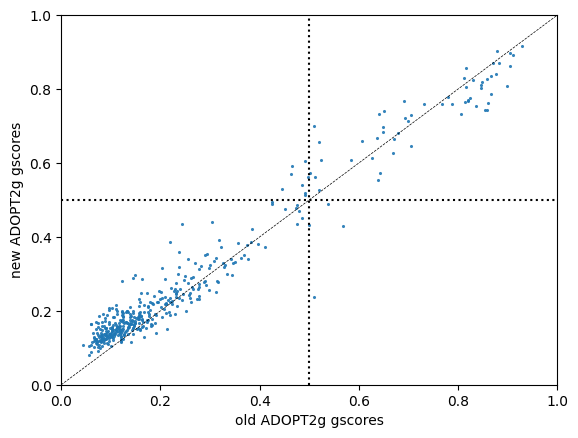

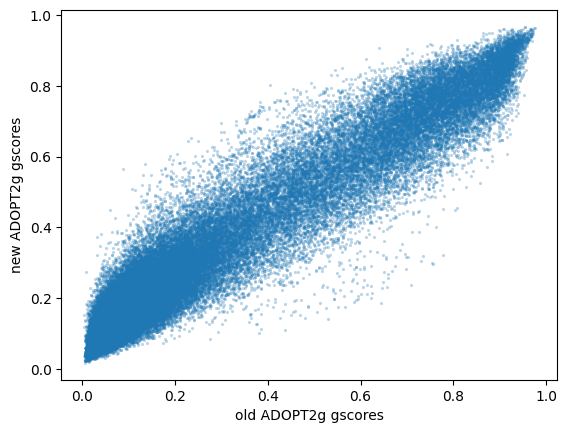

In [11]:
print(f"old: tot_disodered={sum(df_saxs['mean_gscore_adopt2'].values > 0.5)}")
print(f"new: tot_disodered={sum(df_saxs_new['mean_gscore'].values > 0.5)}")
max_diff_label = df_saxs.iloc[
    np.argmax(np.abs(df_saxs["mean_gscore_adopt2"].values - df_saxs_new["mean_gscore"].values))
].name
print(f"entry with max diff: {max_diff_label}")
print(f"  old: {df_saxs.loc[max_diff_label, 'mean_gscore_adopt2']}")
print(f"  new: {df_saxs_new.loc[max_diff_label, 'mean_gscore']}")
plt.scatter(
    df_saxs["mean_gscore_adopt2"].values,
    df_saxs_new["mean_gscore"].values,
    alpha=0.9,
    s=5,
    lw=0,
)
plt.axline((0.5, 0.5), slope=1, color="k", ls="--", lw=0.5)
plt.axhline(0.5, color="k", linestyle=":")
plt.axvline(0.5, color="k", linestyle=":")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.xlabel("old ADOPT2g gscores")
plt.ylabel("new ADOPT2g gscores")
plt.show()

plt.scatter(
    np.concatenate(df_saxs["gscores_adopt2"].values),
    np.concatenate(df_saxs_new["gscores"].values),
    alpha=0.3,
    s=5,
    lw=0,
)
plt.xlabel("old ADOPT2g gscores")
plt.ylabel("new ADOPT2g gscores")
plt.show()

In [ ]:
raise SystemError

In [ ]:
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

TRIZOD_FOLDER = "trizod-2025_12_12"
TRIZOD_FILTERING = "tolerant"
NAN_THRESHOLD = 0.5  # Filter out sequences with too many NaN gscores
MIN_LENGTH = 10
MAX_LENGTH = 1000

# Manually curated list of bad entries, with comments
# This could be automated with some LLM...
EXCLUDED_TRIZOD_ENTRIES = {
    "27269_1_1_1": "reduction with TCEP leads to unfolding",
    "6702_1_1_1": "data is actually from a complex, alone it's an IDP",
}

In [ ]:
# Load trizod data
trizod_data = {}
if not os.path.exists(f"{TRIZOD_FOLDER}/{TRIZOD_FILTERING}.json"):
    raise FileNotFoundError(f"File {TRIZOD_FOLDER}/{TRIZOD_FILTERING}.json not found. It should be crated with TriZOD")
with open(f"{TRIZOD_FOLDER}/{TRIZOD_FILTERING}.json") as f:
    for line in f:
        d = json.loads(line)
        nan_ratio = sum(g is None or (isinstance(g, float) and np.isnan(g)) for g in d["gscores"]) / len(d["gscores"])
        if (
            nan_ratio < NAN_THRESHOLD
            and len(d["seq"]) >= MIN_LENGTH
            and len(d["seq"]) <= MAX_LENGTH
            and d["ID"] not in EXCLUDED_TRIZOD_ENTRIES
        ):
            trizod_data[d["ID"]] = {
                prop: d[prop]
                for prop in ["seq", "entity_name", "temperature", "pH", "ionic_strength", "total_bbshifts", "gscores"]
            }
            trizod_data[d["ID"]]["gscores"] = np.array(trizod_data[d["ID"]]["gscores"], dtype=float)
            trizod_data[d["ID"]]["mean_gscore"] = np.nanmean(trizod_data[d["ID"]]["gscores"])

print(f"Loaded {len(trizod_data):_} trizod entries (filtered from {TRIZOD_FILTERING}.json)")

In [ ]:
predictions_file = f"{TRIZOD_FOLDER}/predicted-{TRIZOD_FILTERING}.csv"
if not os.path.exists(predictions_file):
    with open(f"{TRIZOD_FOLDER}/{TRIZOD_FILTERING}.fasta", "w") as f:
        for label, d in trizod_data.items():
            f.write(f">{label}\n{d['seq']}\n")
    !adpt2g-predict --in {TRIZOD_FOLDER}/{TRIZOD_FILTERING}.fasta --out {predictions_file}
df_predicted = pd.read_csv(
    predictions_file,
    index_col="label",
    converters={"gscores": lambda x: np.array(json.loads(x), dtype=float)},
)
df_predicted

In [ ]:
# largest mae:
trizod_df = pd.DataFrame.from_dict(trizod_data, orient="index")
assert trizod_df.index.equals(df_predicted.index)

plt.scatter(trizod_df["mean_gscore"].values, df_predicted["mean_gscore"].values, s=5, lw=0, alpha=0.5)
plt.ylim(0, 1)
plt.xlim(0, 1)
plt.axline((0, 0), (1, 1), color="black", ls=":")
delta_mae = 0.5
x = np.linspace(0, 1, 200)
plt.fill_between(
    x,
    np.clip(x - delta_mae, 0, 1),
    np.clip(x + delta_mae, 0, 1),
    color="grey",
    alpha=0.2,
    label=f"|y-x| ≤ {delta_mae}",
)

plt.xlabel("Trizod mean gscore")
plt.ylabel("Predicted mean gscore")
plt.title("Predicted vs Trizod mean gscore")
plt.show()

individual_mae = np.abs(trizod_df["mean_gscore"].values - df_predicted["mean_gscore"].values)
top_mae_indices = np.argsort(-individual_mae)
top_mae_indices = top_mae_indices[individual_mae[top_mae_indices] > delta_mae]
print(f"total entries above {delta_mae} MAE: {len(top_mae_indices)}\n")
for i, idx in enumerate(top_mae_indices):
    length = len(df_predicted["sequence"].iloc[idx])
    print(
        f"{df_predicted['mean_gscore'].iloc[idx] - trizod_df['mean_gscore'].iloc[idx]:.3f}, "
        f"{length}, {np.isnan(trizod_df['gscores'].iloc[idx]).sum() / length:.2%}, "
        f"{np.isnan(df_predicted['gscores'].iloc[idx]).sum() / length}, "
        f"{df_predicted['mean_gscore'].iloc[idx]:.3f}, {trizod_df.iloc[idx]}\n\n",
    )